# Predicción de demanda diaria de repostería en una panadería francesa

**Proyecto final — Data Science (Coderhouse)**
**Autor:** Diego Valencia Chica

**Índice**
1. Formulación del problema
2. Carga de datos
3. Análisis exploratorio de datos (EDA)
4. Ingeniería de atributos
5. Entrenamiento de modelos
6. Optimización de hiperparámetros
7. Selección y evaluación del modelo
8. Explicabilidad con SHAP
9. Conclusiones

## 1. Formulación del problema

**Contexto de negocio.** Una panadería y repostería artesanal francesa hornea cada mañana croissants, pains au chocolat, tartaletas, éclairs y otros productos de repostería. Son productos perecederos, porque lo que no se vende en el día se pierde. Si la panadería hornea de más, tira producto (merma). Si hornea de menos, pierde ventas y deja clientes insatisfechos. Hoy la cantidad a hornear se decide por intuición.

**Pregunta problema.** ¿Cuántas unidades de cada producto de repostería se van a vender mañana?

| Elemento | Definición |
|---|---|
| Tipo de tarea | **Regresión** supervisada. El objetivo es una cantidad continua y no negativa. |
| Unidad de análisis | Un producto en un día de apertura |
| Variable objetivo | `unidades`: unidades vendidas del producto ese día |
| Métrica principal | **RMSE** (raíz del error cuadrático medio), en unidades |
| Métricas de apoyo | **MAE** (error absoluto medio) y **R²** |

**Por qué RMSE.** El RMSE penaliza más los errores grandes. En una panadería, errar por 30 croissants un domingo de agosto cuesta mucho más que errar por 1 éclair un martes de febrero, en merma o en ventas perdidas. El RMSE está en la misma unidad que la variable objetivo, así que se puede traducir directo a producción. El MAE se usa para pasar el error a euros en la sección 7.

**Criterio de éxito.** El modelo tiene que superar con claridad a la regla simple que usaría hoy el panadero, que es *"hornear lo mismo que el mismo día de la semana pasada"* (baseline ingenuo).

**Dataset.** [French Bakery Daily Sales](https://www.kaggle.com/datasets/matthieugimbert/french-bakery-daily-sales) (Kaggle). Contiene 234.005 líneas de tickets de una panadería en Francia, entre enero de 2021 y septiembre de 2022.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import shap

from src.utils import (cargar_transacciones, ventas_diarias, crear_atributos,
                       PRODUCTOS, VIENNOISERIE, PATISSERIE, SEED)

np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Versiones -> pandas", pd.__version__, "| xgboost", __import__("xgboost").__version__, "| shap", shap.__version__)

Versiones -> pandas 3.0.3 | xgboost 3.4.1 | shap 0.54.1


## 2. Carga de datos

La lectura y la corrección de tipos están en `src/utils.py`, para que el notebook quede limpio y el proceso se pueda reproducir. El precio original viene como texto con formato francés (`"0,90 €"`) y se convierte a número.

In [2]:
trx = cargar_transacciones()
print("Filas x columnas:", trx.shape)
trx.head()

Filas x columnas: (234005, 6)


,date,time,ticket_number,article,Quantity,unit_price
0,2021-01-02,08:38,150040,BAGUETTE,1.0,0.90
1,2021-01-02,08:38,150040,PAIN AU CHOCOLAT,3.0,1.20
2,2021-01-02,09:14,150041,PAIN AU CHOCOLAT,2.0,1.20
3,2021-01-02,09:14,150041,PAIN,1.0,1.15
4,2021-01-02,09:25,150042,TRADITIONAL BAGUETTE,5.0,1.20


In [3]:
trx.info()

<class 'pandas.DataFrame'>
RangeIndex: 234005 entries, 0 to 234004
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   date           234005 non-null  datetime64[us]
 1   time           234005 non-null  str           
 2   ticket_number  234005 non-null  int64         
 3   article        234005 non-null  str           
 4   Quantity       234005 non-null  float64       
 5   unit_price     234005 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(2)
memory usage: 10.7 MB


## 3. Análisis exploratorio de datos (EDA)

### 3.1 Calidad de los datos: nulos, duplicados y valores inválidos

In [4]:
calidad = pd.Series({
    "Valores nulos (total)": int(trx.isna().sum().sum()),
    "Filas duplicadas exactas": int(trx.duplicated().sum()),
    "Cantidades <= 0 (devoluciones/anulaciones)": int((trx["Quantity"] <= 0).sum()),
    "Precios iguales a 0": int((trx["unit_price"] == 0).sum()),
    "Productos distintos": trx["article"].nunique(),
    "Días con ventas": trx["date"].nunique(),
    "Desde": trx["date"].min().date(),
    "Hasta": trx["date"].max().date(),
})
calidad.to_frame("valor")

,valor
Valores nulos (total),0
Filas duplicadas exactas,1210
Cantidades <= 0 (devoluciones/anulaciones),1295
Precios iguales a 0,32
Productos distintos,149
Días con ventas,600
Desde,2021-01-02
Hasta,2022-09-30


In [5]:
trx[["Quantity", "unit_price"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,234005.0,1.538377,1.289603,-200.0,1.0,1.0,2.0,200.0
unit_price,234005.0,1.662195,1.722720,0.0,1.1,1.2,1.5,60.0


**Hallazgos y problemas detectados**
- No hay **valores nulos**, pero el precio venía como texto y había que convertirlo.
- Hay **cantidades negativas o en cero**. Son devoluciones o anulaciones de ticket, no demanda real, así que se excluyen al construir la variable objetivo.
- Las **filas duplicadas** comparten ticket, hora, producto y cantidad. En un registro de caja eso pasa cuando el cajero escanea dos veces el mismo producto en el mismo ticket, que es una venta legítima. Por eso se **mantienen**.
- Hay unos pocos **precios en 0**, que corresponden a regalos o promociones. No afectan a la cantidad vendida.
- Hay 149 artículos, que mezclan pan, bebidas, sándwiches y repostería. El proyecto se enfoca en **repostería**.

### 3.2 ¿Qué vende la panadería? Peso de la repostería

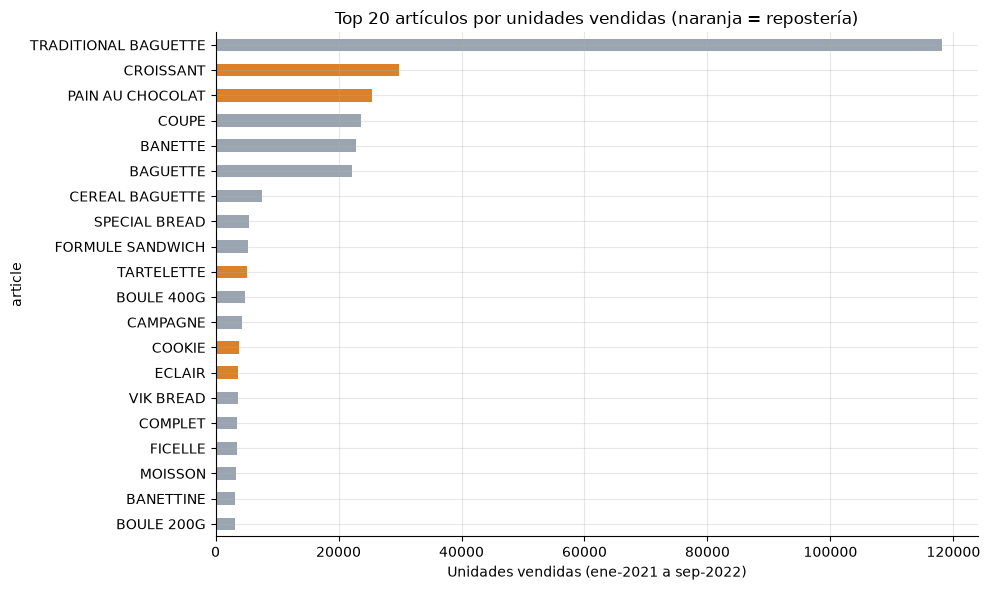

Repostería: 86,952 unidades | 24.3% de la facturación total


In [6]:
top = trx[trx["Quantity"] > 0].groupby("article")["Quantity"].sum().sort_values().tail(20)
colores = ["#d9822b" if a in PRODUCTOS else "#9aa5b1" for a in top.index]
ax = top.plot.barh(color=colores, figsize=(10, 6))
ax.set_title("Top 20 artículos por unidades vendidas (naranja = repostería)")
ax.set_xlabel("Unidades vendidas (ene-2021 a sep-2022)")
plt.tight_layout(); plt.show()

rep = trx[trx["article"].isin(PRODUCTOS) & (trx["Quantity"] > 0)]
ingresos = (trx["Quantity"] * trx["unit_price"]).clip(lower=0)
print(f"Repostería: {rep['Quantity'].sum():,.0f} unidades | "
      f"{(rep['Quantity']*rep['unit_price']).sum() / ingresos.sum():.1%} de la facturación total")

**Insight.** Después de la baguette tradicional, los dos productos más vendidos de toda la panadería son de repostería: el **croissant** y el **pain au chocolat**. Los 16 productos de repostería seleccionados explican cerca del **24 % de la facturación total**, y es la categoría con más riesgo de merma. Eso justifica enfocar el modelo en ella. Se seleccionaron los **16 productos** de repostería con volumen suficiente para modelar: 8 de viennoiserie y 8 de pâtisserie.

### 3.3 Distribución de las cantidades por ticket (outliers a nivel transacción)

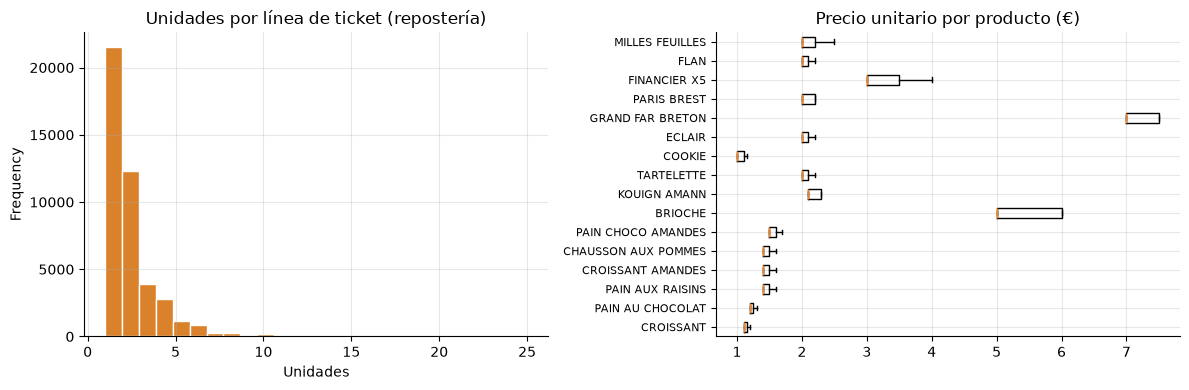

count    43358.00
mean         2.01
std          1.54
min          1.00
90%          4.00
99%          8.00
99.9%       12.00
max         25.00
Name: Quantity, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rep["Quantity"].plot.hist(bins=25, ax=axes[0], color="#d9822b", edgecolor="white")
axes[0].set_title("Unidades por línea de ticket (repostería)"); axes[0].set_xlabel("Unidades")
axes[1].boxplot([rep.loc[rep["article"] == p, "unit_price"] for p in PRODUCTOS], vert=False)
axes[1].set_yticks(range(1, len(PRODUCTOS) + 1), PRODUCTOS, fontsize=8)
axes[1].set_title("Precio unitario por producto (€)")
plt.tight_layout(); plt.show()
print(rep["Quantity"].describe(percentiles=[.9, .99, .999]).round(2))

**Insight.** La mayoría de los clientes compra 1 o 2 unidades. El máximo es 25, que corresponde a pedidos de grupo o familia. Son compras **reales y plausibles**, no errores de carga, así que se mantienen. Los precios unitarios son estables dentro de cada producto. Los pequeños saltos que se ven corresponden a aumentos de precio, que se analizan en 3.6.

### 3.4 Construcción de la variable objetivo: ventas diarias por producto

Se agregan las transacciones a **unidades vendidas por producto y por día de apertura**. Si un producto no se vendió en un día en que la panadería abrió, su venta es **0**. Esto es un dato, no un faltante.

In [8]:
diario = ventas_diarias(trx)
print("Filas:", diario.shape[0], "=", diario["date"].nunique(), "días x", len(PRODUCTOS), "productos")
diario.head()

Filas: 9600 = 600 días x 16 productos


,date,article,unidades,precio
0,2021-01-02,CROISSANT,66.0,1.1
1,2021-01-02,PAIN AU CHOCOLAT,48.0,1.2
2,2021-01-02,PAIN AUX RAISINS,6.0,1.4
3,2021-01-02,CROISSANT AMANDES,0.0,1.4
4,2021-01-02,CHAUSSON AUX POMMES,0.0,1.4


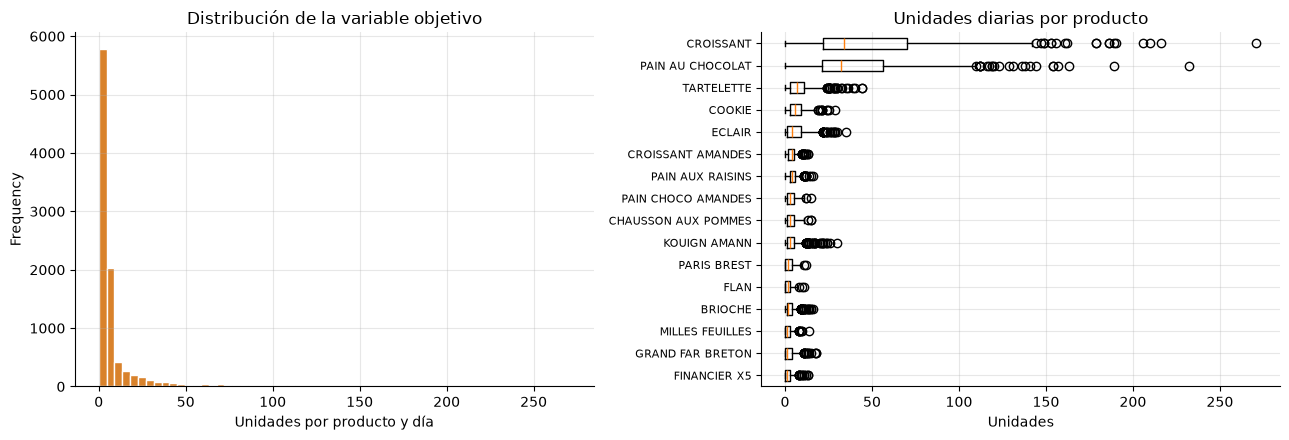

,count,mean,std,min,25%,50%,75%,max
article,,,,,,,,
CROISSANT,600.0,49.7,39.4,0.0,22.0,34.0,70.0,271.0
PAIN AU CHOCOLAT,600.0,42.3,30.5,0.0,21.0,32.0,56.2,232.0
TARTELETTE,600.0,8.4,7.3,0.0,3.0,7.0,11.0,44.0
COOKIE,600.0,6.3,4.4,0.0,3.0,6.0,9.0,29.0
ECLAIR,600.0,6.1,6.4,0.0,1.0,4.0,9.0,35.0
PAIN AUX RAISINS,600.0,4.6,2.5,0.0,3.0,4.0,6.0,16.0
KOUIGN AMANN,600.0,4.0,4.4,0.0,1.0,3.0,5.2,30.0
CROISSANT AMANDES,600.0,3.9,2.6,0.0,2.0,4.0,5.0,13.0
PAIN CHOCO AMANDES,600.0,3.2,2.4,0.0,1.0,3.0,5.0,15.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
diario["unidades"].plot.hist(bins=60, ax=axes[0], color="#d9822b", edgecolor="white")
axes[0].set_title("Distribución de la variable objetivo"); axes[0].set_xlabel("Unidades por producto y día")
orden = diario.groupby("article")["unidades"].median().sort_values().index
axes[1].boxplot([diario.loc[diario["article"] == p, "unidades"] for p in orden], vert=False)
axes[1].set_yticks(range(1, len(orden) + 1), orden, fontsize=8)
axes[1].set_title("Unidades diarias por producto"); axes[1].set_xlabel("Unidades")
plt.tight_layout(); plt.show()
diario.groupby("article")["unidades"].describe().round(1).sort_values("mean", ascending=False)

**Insight.** La variable objetivo tiene una **asimetría positiva fuerte**. Hay dos productos de alto volumen, croissant y pain au chocolat, con unos 40 a 50 por día, y catorce productos de bajo volumen, de 2 a 8 por día y con muchos días en cero. Las escalas son muy distintas, así que el producto tiene que ser una variable del modelo.

### 3.5 Outliers en la serie diaria (criterio IQR)

In [10]:
q1 = diario.groupby("article")["unidades"].transform(lambda s: s.quantile(.25))
q3 = diario.groupby("article")["unidades"].transform(lambda s: s.quantile(.75))
outlier = diario["unidades"] > q3 + 1.5 * (q3 - q1)
o = diario[outlier]
print(f"Días-producto atípicos: {outlier.sum()} ({outlier.mean():.1%})")
print(f"  - caen en domingo: {(o['date'].dt.dayofweek == 6).mean():.0%}")
print(f"  - caen en julio/agosto: {o['date'].dt.month.isin([7, 8]).mean():.0%}")

Días-producto atípicos: 264 (2.8%)
  - caen en domingo: 53%
  - caen en julio/agosto: 67%


**Decisión.** Los valores atípicos no son errores. Se concentran en **domingos y en julio y agosto**, que son justamente los picos de demanda que el negocio necesita anticipar. Si se eliminaran, el modelo subestimaría los días más importantes. Por eso se **mantienen**, y se le agregan al modelo variables que los explican (día de la semana, temporada alta). Además, los modelos basados en árboles son robustos frente a valores extremos.

### 3.6 Patrones temporales: tendencia, semana y estacionalidad

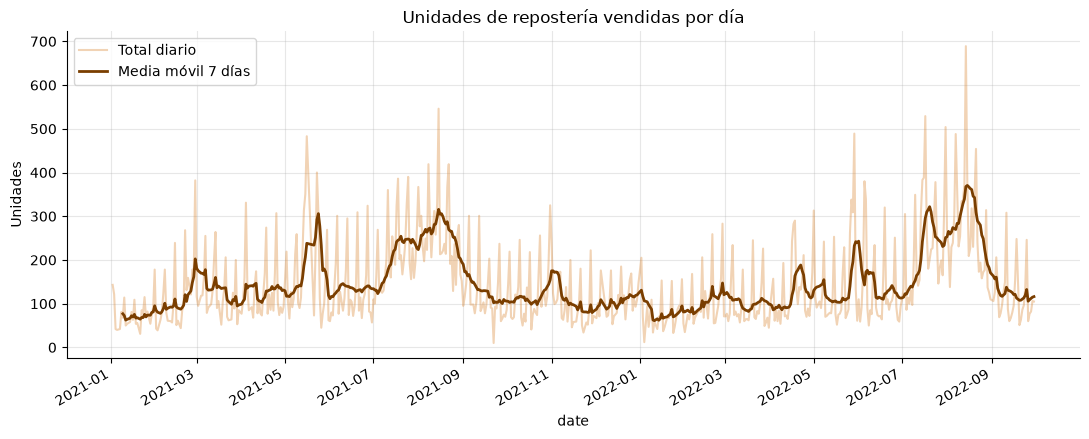

In [11]:
total = diario.groupby("date")["unidades"].sum()
ax = total.plot(alpha=0.35, color="#d9822b", label="Total diario")
total.rolling(7).mean().plot(ax=ax, color="#7a3e00", lw=2, label="Media móvil 7 días")
ax.set_title("Unidades de repostería vendidas por día"); ax.set_ylabel("Unidades"); ax.legend()
plt.tight_layout(); plt.show()

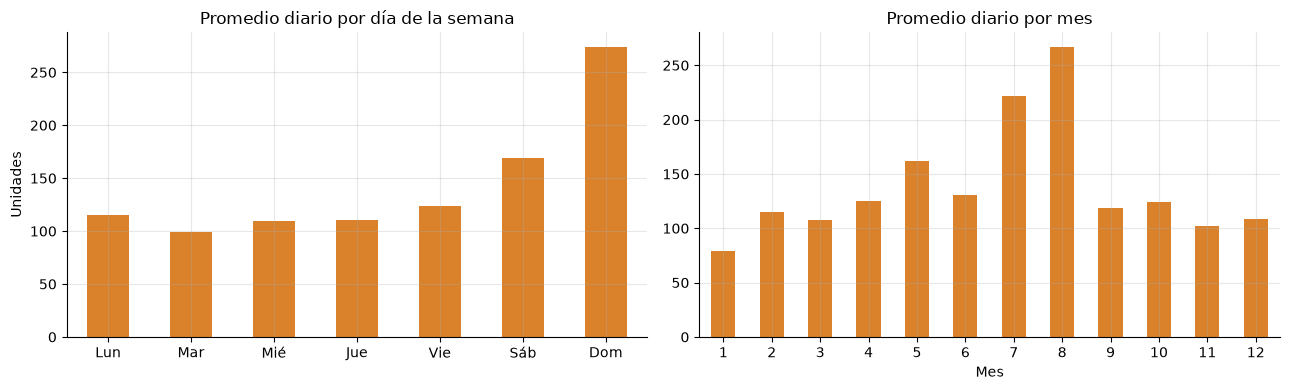

Días sin ventas (cerrado): 37 | de ellos, miércoles: 29


In [12]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
total.groupby(total.index.dayofweek).mean().set_axis(dias).plot.bar(ax=axes[0], color="#d9822b", rot=0)
axes[0].set_title("Promedio diario por día de la semana"); axes[0].set_ylabel("Unidades")
total.groupby(total.index.month).mean().plot.bar(ax=axes[1], color="#d9822b", rot=0)
axes[1].set_title("Promedio diario por mes"); axes[1].set_xlabel("Mes")
plt.tight_layout(); plt.show()

cerrados = pd.date_range(total.index.min(), total.index.max()).difference(total.index)
print(f"Días sin ventas (cerrado): {len(cerrados)} | de ellos, miércoles: {(cerrados.dayofweek == 2).sum()}")

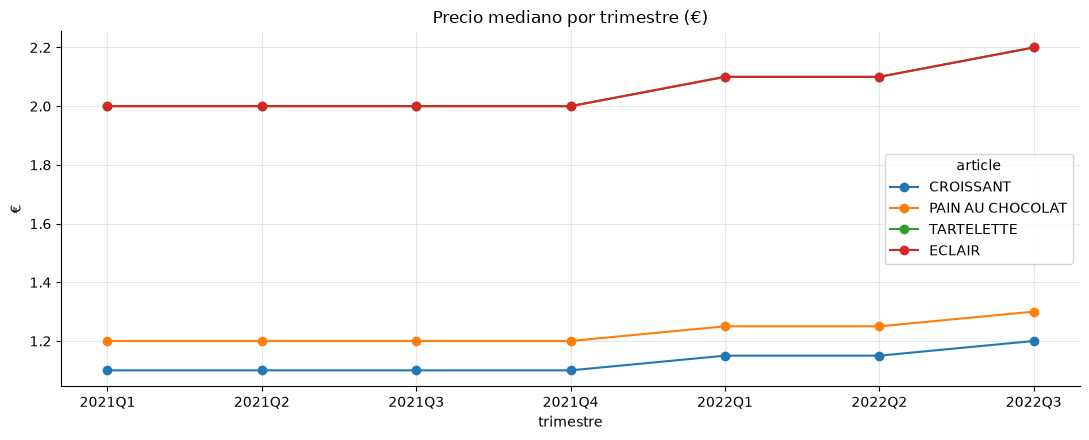

In [13]:
precios = (rep.assign(trimestre=rep["date"].dt.to_period("Q").astype(str))
              .groupby(["trimestre", "article"])["unit_price"].median().unstack()
              [["CROISSANT", "PAIN AU CHOCOLAT", "TARTELETTE", "ECLAIR"]])
ax = precios.plot(marker="o"); ax.set_title("Precio mediano por trimestre (€)"); ax.set_ylabel("€")
plt.tight_layout(); plt.show()

**Insights clave**
1. **El domingo domina la semana.** Se vende más del doble que un día hábil promedio. El sábado también está por encima.
2. **Estacionalidad turística fuerte.** En julio y agosto la demanda se duplica respecto del resto del año, lo que sugiere una zona turística.
3. **Cierre semanal.** La panadería cierra la mayoría de los miércoles de temporada baja. Esos días no son faltantes, porque no hubo actividad, y quedan fuera del análisis.
4. **Aumento de precios en 2022**, de entre +5 y +10 %, por la inflación. El precio entra como variable para que el modelo lo considere.
5. Hay **dependencia temporal**: la venta de un día se parece a la de días recientes. Esto justifica crear variables de historia (lags) y obliga a validar respetando el orden del tiempo.

## 4. Ingeniería de atributos

Las variables se construyen en `crear_atributos()` (`src/utils.py`). **Regla anti-fuga:** toda variable de historia usa solo datos **anteriores** al día que se predice (`shift(1)`), igual que tendría el panadero la noche anterior.

| Variable | Tipo | Justificación |
|---|---|---|
| `dia_semana`, `fin_de_semana`, `domingo` | Calendario | Patrón semanal muy marcado (EDA 3.6) |
| `mes`, `temporada_alta` (jul-ago) | Calendario | Estacionalidad turística |
| `feriado` | Calendario | Los feriados franceses cambian la afluencia |
| `categoria` | Agregación de producto | Viennoiserie y pâtisserie tienen dinámicas distintas |
| `article` | Categórica | Cada producto tiene su propio nivel de venta |
| `precio` | Numérica | Captura los aumentos de 2022 |
| `lag_1` | Historia | Venta del día de apertura anterior |
| `lag_semana` | Historia | Venta del mismo día de la semana anterior (la "regla del panadero") |
| `media_7`, `media_28`, `max_7` | Agregaciones móviles | Nivel reciente y tendencia, suavizan el ruido diario |

Se descartan los primeros 28 días de cada producto, porque todavía no tienen historia suficiente para calcular `media_28`.

In [14]:
datos = crear_atributos(diario)
print("Dataset de modelado:", datos.shape)
datos.head()

Dataset de modelado: (9152, 16)


,date,article,unidades,precio,dia_semana,mes,fin_de_semana,domingo,feriado,temporada_alta,categoria,lag_1,media_7,media_28,max_7,lag_semana
0,2021-02-04,BRIOCHE,2.0,5.0,3,2,0,0,0,0,viennoiserie,0.0,1.285714,1.250000,3.0,2.0
1,2021-02-05,BRIOCHE,1.0,5.0,4,2,0,0,0,0,viennoiserie,2.0,1.428571,1.250000,3.0,2.0
2,2021-02-06,BRIOCHE,1.0,5.0,5,2,1,0,0,0,viennoiserie,1.0,1.285714,1.178571,3.0,1.0
3,2021-02-07,BRIOCHE,2.0,5.0,6,2,1,1,0,0,viennoiserie,1.0,1.142857,1.178571,3.0,3.0
4,2021-02-08,BRIOCHE,2.0,5.0,0,2,0,0,0,0,viennoiserie,2.0,1.285714,1.178571,3.0,0.0


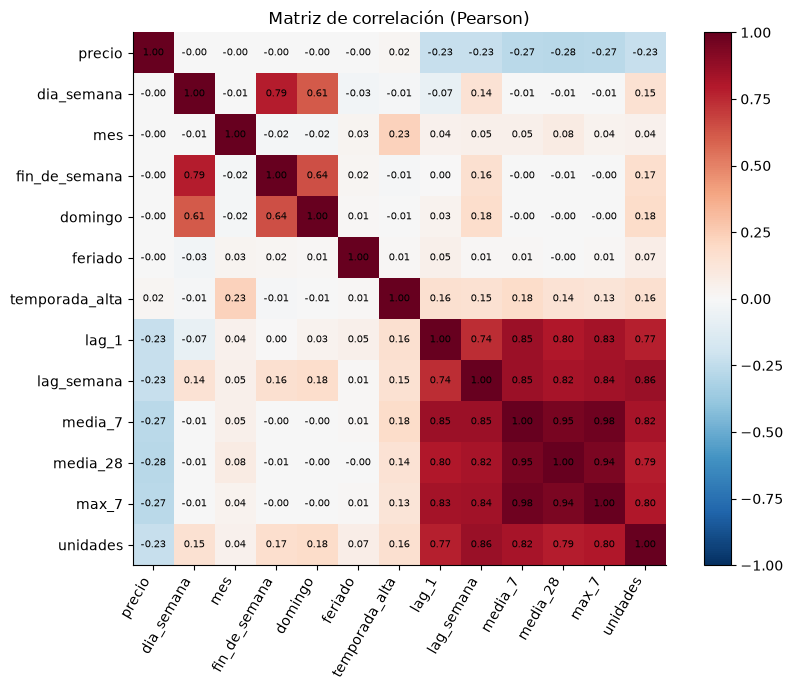

,corr con unidades
lag_semana,0.864
media_7,0.822
max_7,0.803
media_28,0.789
lag_1,0.774
domingo,0.181
fin_de_semana,0.168
temporada_alta,0.162
dia_semana,0.151
feriado,0.065


In [15]:
num_cols = ["precio", "dia_semana", "mes", "fin_de_semana", "domingo", "feriado", "temporada_alta",
            "lag_1", "lag_semana", "media_7", "media_28", "max_7"]
cat_cols = ["article", "categoria"]
objetivo = "unidades"

corr = datos[num_cols + [objetivo]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Matriz de correlación (Pearson)"); ax.grid(False)
plt.tight_layout(); plt.show()
corr[objetivo].drop(objetivo).sort_values(ascending=False).round(3).to_frame("corr con unidades")

**Lectura.** Las variables de historia (`lag_semana`, `media_7`, `media_28`, `max_7`) son las más correlacionadas con la variable objetivo. También están muy correlacionadas entre sí, que es multicolinealidad esperable porque miden el nivel reciente del producto. Para un modelo lineal esto se controla con **regularización (Ridge)**. Para los modelos de árboles no es un problema.

### Encoding y escalado

Se aplican dentro de un `Pipeline` de scikit-learn, así las transformaciones se ajustan **solo con datos de entrenamiento**:
- **One-Hot Encoding** para `article` y `categoria`, porque son categorías nominales sin orden.
- **StandardScaler** para las variables numéricas, solo en el modelo lineal, que es sensible a la escala. Los árboles no lo necesitan, y sin escalar los valores de SHAP quedan en las unidades originales, lo que facilita leerlos.

In [16]:
prep_lineal = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
], verbose_feature_names_out=False)

prep_arbol = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
], verbose_feature_names_out=False)

## 5. Entrenamiento de modelos

### 5.1 División train / validación temporal

Es una serie temporal, así que **no se mezcla al azar**: sería entrenar con el futuro para predecir el pasado. Se separa por fecha:
- **Entrenamiento:** hasta el 30-jun-2022.
- **Validación (test final):** del 1-jul-2022 al 30-sep-2022. Son los 3 últimos meses, que incluyen la temporada alta, el período más exigente para el negocio.

In [17]:
corte = pd.Timestamp("2022-07-01")
datos = datos.sort_values(["date", "article"]).reset_index(drop=True)
train, test = datos[datos["date"] < corte], datos[datos["date"] >= corte]

X_train, y_train = train[num_cols + cat_cols], train[objetivo]
X_test, y_test = test[num_cols + cat_cols], test[objetivo]
print(f"Train: {len(train):,} filas ({train['date'].min().date()} a {train['date'].max().date()})")
print(f"Test : {len(test):,} filas ({test['date'].min().date()} a {test['date'].max().date()})")

Train: 7,712 filas (2021-02-04 a 2022-06-30)
Test : 1,440 filas (2022-07-01 a 2022-09-30)


### 5.2 Baseline del negocio y modelos iniciales

Se entrenan cuatro modelos supervisados con parámetros razonables por defecto:
- **Ridge**: regresión lineal regularizada, el modelo simple e interpretable.
- **Árbol de decisión**.
- **Random Forest** (bagging).
- **XGBoost** (boosting).

Todos se comparan contra la **regla del panadero** (`lag_semana`).

In [18]:
def metricas(y_real, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
            "MAE": mean_absolute_error(y_real, y_pred),
            "R2": r2_score(y_real, y_pred)}

tscv = TimeSeriesSplit(n_splits=5)

modelos_base = {
    "Ridge": Pipeline([("prep", prep_lineal), ("modelo", Ridge(alpha=1.0))]),
    "Árbol de decisión": Pipeline([("prep", prep_arbol), ("modelo", DecisionTreeRegressor(random_state=SEED))]),
    "Random Forest": Pipeline([("prep", prep_arbol), ("modelo", RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1))]),
    "XGBoost": Pipeline([("prep", prep_arbol), ("modelo", XGBRegressor(n_estimators=300, learning_rate=0.05, random_state=SEED, n_jobs=-1))]),
}

resultados = [{"Modelo": "Baseline: mismo día semana anterior", "Etapa": "baseline",
               **{f"Test {k}": v for k, v in metricas(y_test, test["lag_semana"]).items()}}]
for nombre, pipe in modelos_base.items():
    t0 = time.time()
    cv = -cross_val_score(pipe, X_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error")
    pipe.fit(X_train, y_train)
    resultados.append({"Modelo": nombre, "Etapa": "inicial",
                       "CV RMSE": cv.mean(), "CV RMSE std": cv.std(),
                       "Train RMSE": metricas(y_train, pipe.predict(X_train))["RMSE"],
                       **{f"Test {k}": v for k, v in metricas(y_test, pipe.predict(X_test)).items()},
                       "Tiempo (s)": time.time() - t0})
pd.DataFrame(resultados).set_index("Modelo").round(3)

,Etapa,Test RMSE,Test MAE,Test R2,CV RMSE,CV RMSE std,Train RMSE,Tiempo (s)
Modelo,,,,,,,,
Baseline: mismo día semana anterior,baseline,13.003,5.950,0.769,NaN,NaN,NaN,NaN
Ridge,inicial,11.009,5.118,0.835,8.389,2.053,8.083,0.167
Árbol de decisión,inicial,11.743,5.717,0.812,9.467,1.924,0.000,0.311
Random Forest,inicial,9.137,4.280,0.886,7.069,1.959,2.168,5.782
XGBoost,inicial,9.729,4.308,0.871,7.959,2.775,2.729,3.563


**Lectura de los modelos iniciales.** Todos los modelos de ML superan al baseline del negocio. El **árbol de decisión sin restricciones** tiene un error de entrenamiento cercano a 0 y un error de validación mucho mayor, que es un caso claro de **overfitting**: memoriza los datos en vez de generalizar. Los ensambles (Random Forest y XGBoost) generalizan mejor. Esto motiva la optimización de hiperparámetros.

## 6. Optimización de hiperparámetros

Se usa **validación cruzada temporal** (`TimeSeriesSplit`, 5 folds): cada fold entrena con el pasado y valida con el período siguiente. El criterio a optimizar es la métrica objetivo, el **RMSE**.
- **GridSearchCV** para los modelos con pocos hiperparámetros (Ridge y Árbol).
- **RandomizedSearchCV** para Random Forest y XGBoost, porque el espacio de búsqueda es grande y probar todas las combinaciones sería costoso.

In [19]:
busquedas = {
    "Ridge": GridSearchCV(modelos_base["Ridge"],
        {"modelo__alpha": [0.01, 0.1, 1, 10, 100]},
        cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1),
    "Árbol de decisión": GridSearchCV(modelos_base["Árbol de decisión"],
        {"modelo__max_depth": [4, 6, 8, 10, 12], "modelo__min_samples_leaf": [5, 10, 20, 40]},
        cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1),
    "Random Forest": RandomizedSearchCV(modelos_base["Random Forest"],
        {"modelo__n_estimators": [200, 300, 500], "modelo__max_depth": [6, 8, 10, 14, None],
         "modelo__min_samples_leaf": [1, 3, 5, 10], "modelo__max_features": [0.3, 0.5, 0.8, 1.0]},
        n_iter=15, cv=tscv, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1),
    "XGBoost": RandomizedSearchCV(modelos_base["XGBoost"],
        {"modelo__n_estimators": [200, 400, 600, 800], "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
         "modelo__max_depth": [3, 4, 5, 6, 8], "modelo__subsample": [0.7, 0.8, 1.0],
         "modelo__colsample_bytree": [0.6, 0.8, 1.0], "modelo__min_child_weight": [1, 3, 5, 10],
         "modelo__reg_lambda": [0.5, 1, 5, 10]},
        n_iter=30, cv=tscv, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1),
}

mejores = {}
for nombre, busq in busquedas.items():
    t0 = time.time()
    busq.fit(X_train, y_train)
    mejores[nombre] = busq.best_estimator_
    i = busq.best_index_
    resultados.append({"Modelo": nombre, "Etapa": "optimizado",
                       "CV RMSE": -busq.best_score_, "CV RMSE std": busq.cv_results_["std_test_score"][i],
                       "Train RMSE": metricas(y_train, busq.predict(X_train))["RMSE"],
                       **{f"Test {k}": v for k, v in metricas(y_test, busq.predict(X_test)).items()},
                       "Tiempo (s)": time.time() - t0})
    print(f"{nombre:18s} mejores parámetros:",
          {k.replace("modelo__", ""): v for k, v in busq.best_params_.items()})

Ridge              mejores parámetros: {'alpha': 100}


Árbol de decisión  mejores parámetros: {'max_depth': 6, 'min_samples_leaf': 5}


Random Forest      mejores parámetros: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': 6}


XGBoost            mejores parámetros: {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


## 7. Selección y evaluación del modelo

### 7.1 Tabla comparativa

In [20]:
tabla = pd.DataFrame(resultados).set_index(["Modelo", "Etapa"]).round(3)
tabla["Brecha train-test"] = (tabla["Test RMSE"] - tabla["Train RMSE"]).round(3)
tabla.sort_values("CV RMSE")

Test RMSE  Test MAE  Test R2  \
Modelo                              Etapa                                      
Random Forest                       optimizado      9.158     4.328    0.885   
                                    inicial         9.137     4.280    0.886   
XGBoost                             optimizado      9.423     4.224    0.879   
Árbol de decisión                   optimizado      9.884     4.607    0.867   
XGBoost                             inicial         9.729     4.308    0.871   
Ridge                               optimizado     10.962     5.074    0.836   
                                    inicial        11.009     5.118    0.835   
Árbol de decisión                   inicial        11.743     5.717    0.812   
Baseline: mismo día semana anterior baseline       13.003     5.950    0.769   

                                                CV RMSE  CV RMSE std  \
Modelo                              Etapa                              
Random Forest                       optimizado    6.953        2.115   
                                    inicial       7.069        1.959   
XGBoost                             optimizado    7.143        2.293   
Árbol de decisión                   optimizado    7.527        2.273   
XGBoost                             inicial       7.959        2.775   
Ridge                               optimizado    8.285        2.151   
                                    inicial       8.389        2.053   
Árbol de decisión                   inicial       9.467        1.924   
Baseline: mismo día semana anterior baseline        NaN          NaN   

                                                Train RMSE  Tiempo (s)  \
Modelo                              Etapa                                
Random Forest                       optimizado       4.958      59.502   
                                    inicial          2.168       5.782   
XGBoost                             optimizado       4.194      28.800   
Árbol de decisión                   optimizado       5.355       1.195   
XGBoost                             inicial          2.729       3.563   
Ridge                               optimizado       8.141       6.858   
                                    inicial          8.083       0.167   
Árbol de decisión                   inicial          0.000       0.311   
Baseline: mismo día semana anterior baseline           NaN         NaN   

                                                Brecha train-test  
Modelo                              Etapa                          
Random Forest                       optimizado              4.200  
                                    inicial                 6.969  
XGBoost                             optimizado              5.229  
Árbol de decisión                   optimizado              4.529  
XGBoost                             inicial                 7.000  
Ridge                               optimizado              2.821  
                                    inicial                 2.926  
Árbol de decisión                   inicial                11.743  
Baseline: mismo día semana anterior baseline                  NaN

**Lectura de la tabla**
- **Todos los modelos superan al baseline del negocio**, que tiene un RMSE en test de 13,0 unidades.
- La optimización **redujo el sobreajuste**. El árbol de decisión pasó de un RMSE de train de 0 (memorización) a 5,4, y su RMSE en test bajó de 11,7 a 9,9. En Random Forest la brecha entre train y test cayó de 7,0 a 4,2, y en XGBoost de 7,0 a 5,2.
- En Random Forest la optimización mejoró la validación cruzada (de 7,07 a 6,95) pero no cambió el RMSE en test (9,14 contra 9,16). Lo que se gana es un modelo **más simple y estable** (profundidad 6) con el mismo nivel de acierto.
- El RMSE en test es mayor que el de validación cruzada porque el test cae en **temporada alta**, donde los volúmenes son más grandes y, por lo tanto, los errores absolutos también.
- El modelo se elige por el **RMSE de validación cruzada**, no por el de test. Así el test queda como una evaluación final independiente y no se usa para tomar decisiones.

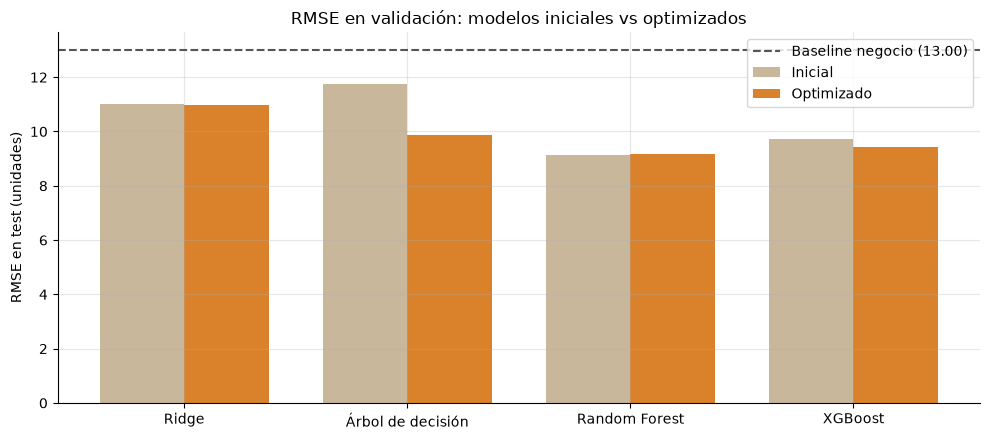

In [21]:
opt = tabla.xs("optimizado", level="Etapa")
ini = tabla.xs("inicial", level="Etapa")
base_rmse = tabla.xs("baseline", level="Etapa")["Test RMSE"].iloc[0]
x = np.arange(len(opt)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w/2, ini.loc[opt.index, "Test RMSE"], w, label="Inicial", color="#c9b79c")
ax.bar(x + w/2, opt["Test RMSE"], w, label="Optimizado", color="#d9822b")
ax.axhline(base_rmse, ls="--", color="#555", label=f"Baseline negocio ({base_rmse:.2f})")
ax.set_xticks(x, opt.index); ax.set_ylabel("RMSE en test (unidades)")
ax.set_title("RMSE en validación: modelos iniciales vs optimizados"); ax.legend()
plt.tight_layout(); plt.show()

In [22]:
mejor_nombre = opt["CV RMSE"].idxmin()  # selección por validación cruzada; el test solo se usa para reportar
modelo_final = mejores[mejor_nombre]
pred = np.clip(modelo_final.predict(X_test), 0, None)  # no existen ventas negativas
m = metricas(y_test, pred)
m_base = metricas(y_test, test["lag_semana"])
print(f"Modelo seleccionado: {mejor_nombre}")
print(f"  RMSE {m['RMSE']:.2f} vs baseline {m_base['RMSE']:.2f}  -> mejora {1 - m['RMSE']/m_base['RMSE']:.1%}")
print(f"  MAE  {m['MAE']:.2f} vs baseline {m_base['MAE']:.2f}  -> mejora {1 - m['MAE']/m_base['MAE']:.1%}")
print(f"  R²   {m['R2']:.3f}")

Modelo seleccionado: Random Forest
  RMSE 9.16 vs baseline 13.00  -> mejora 29.6%
  MAE  4.33 vs baseline 5.95  -> mejora 27.3%
  R²   0.885


### 7.2 Diagnóstico del modelo seleccionado

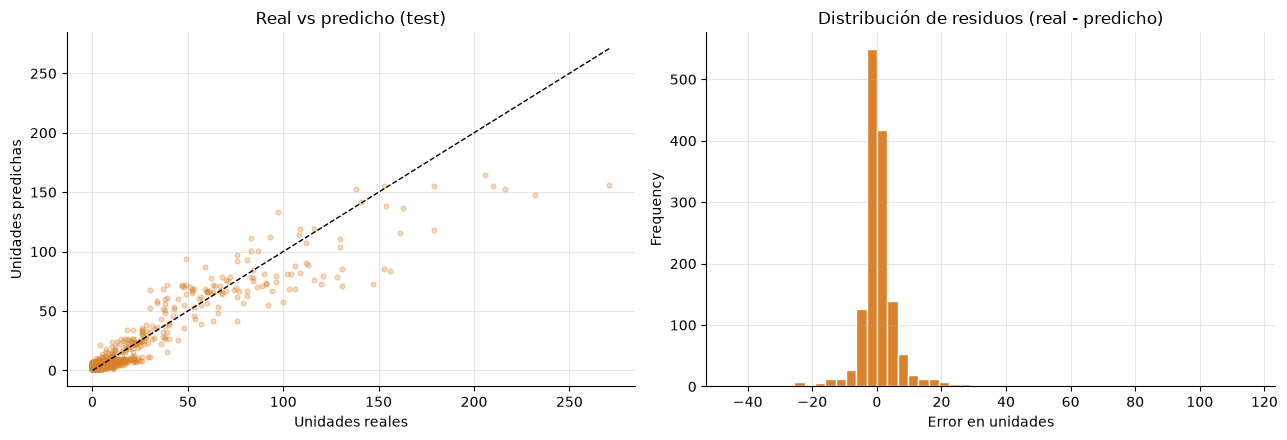

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test, pred, alpha=0.3, s=12, color="#d9822b")
lim = max(y_test.max(), pred.max())
axes[0].plot([0, lim], [0, lim], "k--", lw=1)
axes[0].set_xlabel("Unidades reales"); axes[0].set_ylabel("Unidades predichas")
axes[0].set_title("Real vs predicho (test)")
(y_test - pred).plot.hist(bins=50, ax=axes[1], color="#d9822b", edgecolor="white")
axes[1].set_title("Distribución de residuos (real - predicho)"); axes[1].set_xlabel("Error en unidades")
plt.tight_layout(); plt.show()

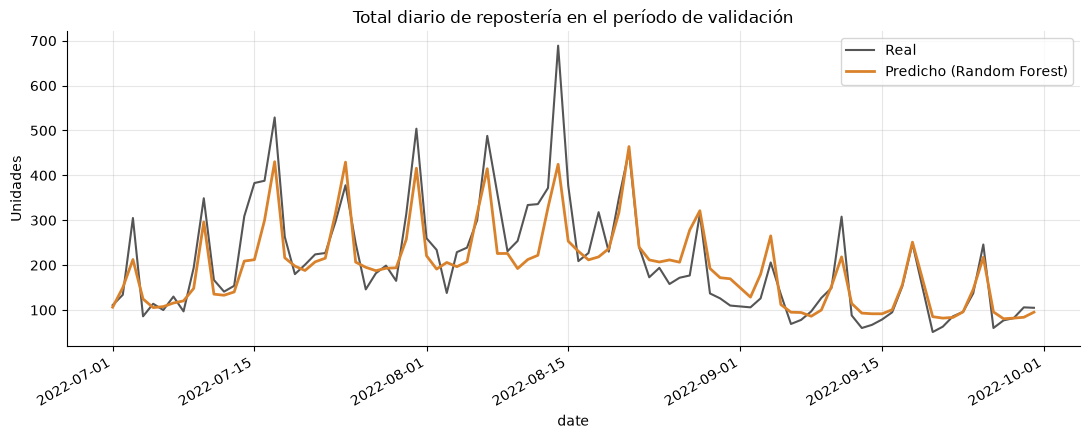

,MAE modelo,MAE baseline,Venta media
article,,,
CROISSANT,19.21,27.93,75.36
PAIN AU CHOCOLAT,13.70,22.08,62.26
TARTELETTE,4.59,5.29,9.78
COOKIE,4.39,5.66,9.26
KOUIGN AMANN,3.89,5.18,7.70
ECLAIR,3.51,4.53,6.73
PAIN AUX RAISINS,2.10,2.49,6.06
CROISSANT AMANDES,2.27,2.82,5.72
GRAND FAR BRETON,2.22,2.87,4.84


In [24]:
serie = test.assign(pred=pred).groupby("date")[["unidades", "pred"]].sum()
ax = serie["unidades"].plot(color="#555", label="Real")
serie["pred"].plot(ax=ax, color="#d9822b", lw=2, label=f"Predicho ({mejor_nombre})")
ax.set_title("Total diario de repostería en el período de validación"); ax.set_ylabel("Unidades"); ax.legend()
plt.tight_layout(); plt.show()

err_prod = (test.assign(pred=pred, base=test["lag_semana"])
                .groupby("article")
                .apply(lambda d: pd.Series({"MAE modelo": mean_absolute_error(d["unidades"], d["pred"]),
                                            "MAE baseline": mean_absolute_error(d["unidades"], d["base"]),
                                            "Venta media": d["unidades"].mean()}))
                .sort_values("Venta media", ascending=False))
err_prod.round(2)

### 7.3 Traducción a impacto de negocio

In [25]:
precio_medio = test["precio"].mean()
dias_test = test["date"].nunique()
err_eur_modelo = (np.abs(y_test - pred) * test["precio"]).sum() / dias_test
err_eur_base = (np.abs(y_test - test["lag_semana"]) * test["precio"]).sum() / dias_test
print(f"Error de producción valorizado (|real - predicho| x precio), promedio por día en jul-sep 2022:")
print(f"  Regla del panadero: {err_eur_base:6.2f} € / día")
print(f"  Modelo {mejor_nombre}: {err_eur_modelo:6.2f} € / día")
print(f"  Reducción: {err_eur_base - err_eur_modelo:6.2f} € / día ({1 - err_eur_modelo / err_eur_base:.0%})")

Error de producción valorizado (|real - predicho| x precio), promedio por día en jul-sep 2022:
  Regla del panadero: 178.68 € / día
  Modelo Random Forest: 133.68 € / día
  Reducción:  45.00 € / día (25%)


**Lectura.** El error valorizado mide cuánto vale el producto que se horneó de más (merma) o de menos (venta perdida). Es una cota aproximada, porque usa el precio de venta y no el costo de producción. Además, el período evaluado es temporada alta, así que el ahorro anual sería menor que multiplicar este valor por 365 días.

### 7.4 Justificación de la elección

La elección combina **métricas** y **criterios de negocio**:
- **Métricas:** el **Random Forest optimizado** tiene el menor RMSE en validación cruzada temporal (6,95). En el test final logra un RMSE de 9,2 unidades frente a 13,0 de la regla actual, es decir un **30 % menos de error**, y un R² de 0,885.
- **Generalización:** con la optimización la brecha entre train y test bajó de 7,0 a 4,2 unidades. Un modelo de profundidad 6 es menos propenso a memorizar el ruido.
- **Costo del error:** en el período de validación, el error valorizado baja de unos 179 € a unos 134 € por día (−25 %). Eso equivale a menos merma y menos ventas perdidas.
- **Precisión donde más importa:** la mejora más grande está en croissant y pain au chocolat, que son los productos de mayor volumen. En los productos de muy baja venta (mille-feuille, paris-brest) el modelo y la regla rinden parecido, porque ahí la demanda es casi aleatoria.
- **Operación:** entrenar el modelo final tarda segundos y la predicción es instantánea. Se puede reentrenar cada noche con las ventas del día.
- **Interpretabilidad:** se puede explicar con SHAP (sección 8), lo que le permite al dueño de la panadería entender y confiar en cada recomendación.

**Alternativas descartadas:** XGBoost queda muy cerca (CV de 7,14) y sería una segunda opción válida. Ridge es más transparente pero claramente menos preciso. El árbol de decisión individual, aun optimizado, queda por detrás de los ensambles.

## 8. Explicabilidad con SHAP

SHAP descompone cada predicción en la contribución de cada variable: cuántas unidades suma o resta cada variable respecto de la predicción promedio. Para modelos de árboles se usa `TreeExplainer`, que es exacto y rápido.

In [26]:
prep_fit = modelo_final.named_steps["prep"]
estimador = modelo_final.named_steps["modelo"]
X_test_t = pd.DataFrame(prep_fit.transform(X_test), columns=prep_fit.get_feature_names_out(), index=X_test.index)

explainer = shap.TreeExplainer(estimador)
shap_values = explainer(X_test_t)

### 8.1 Importancia global: ¿qué variables mueven la demanda?

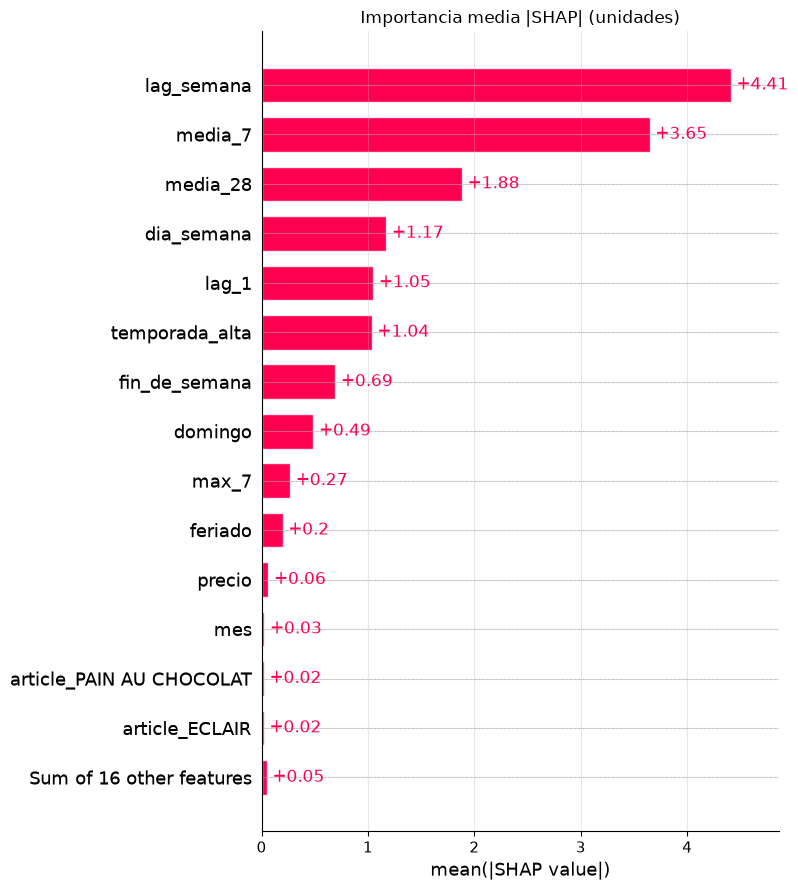

In [27]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Importancia media |SHAP| (unidades)"); plt.tight_layout(); plt.show()

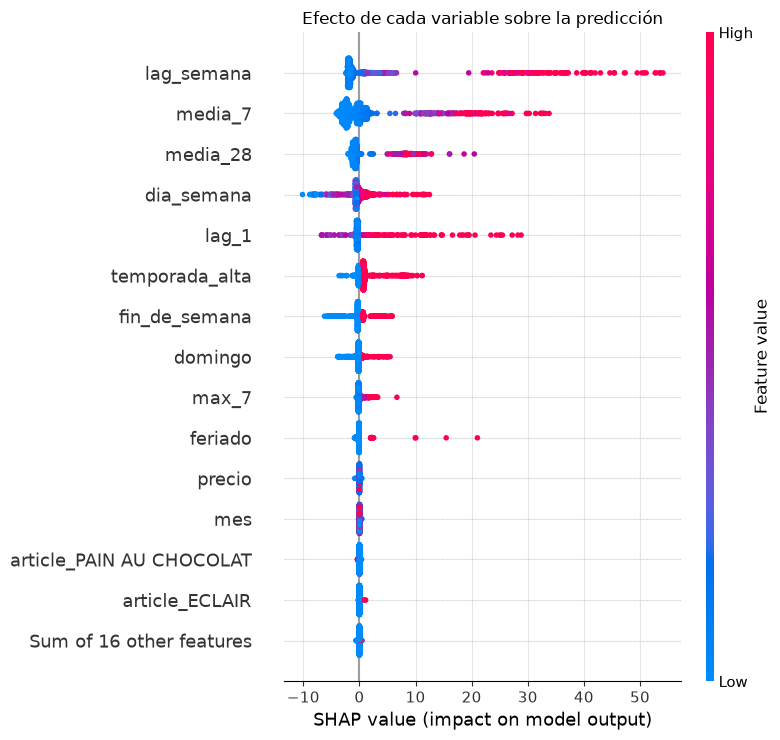

In [28]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("Efecto de cada variable sobre la predicción"); plt.tight_layout(); plt.show()

**Interpretación**
- La variable más influyente es **`lag_semana`**, la venta del mismo día de la semana anterior. Le siguen **`media_7`** y **`media_28`**. El modelo aprovecha la misma intuición que el panadero, pero la combina con el nivel reciente para corregir los días atípicos. Un valor alto (rojo) empuja la predicción hacia arriba.
- El **calendario** viene después: `dia_semana`, `fin_de_semana` y `domingo` suman unidades los fines de semana, y `temporada_alta` las suma en julio y agosto. Esto confirma los patrones del EDA.
- `feriado` tiene un efecto chico pero positivo.
- La identidad del **producto** y el **precio** pesan muy poco. El nivel de venta de cada producto ya está capturado en sus variables de historia, y los aumentos de precio fueron pequeños y no cambiaron la demanda de forma visible.

### 8.2 Explicación de una predicción individual

CROISSANT | 2022-07-03 (domingo) | real: 96 | predicho: 74.2


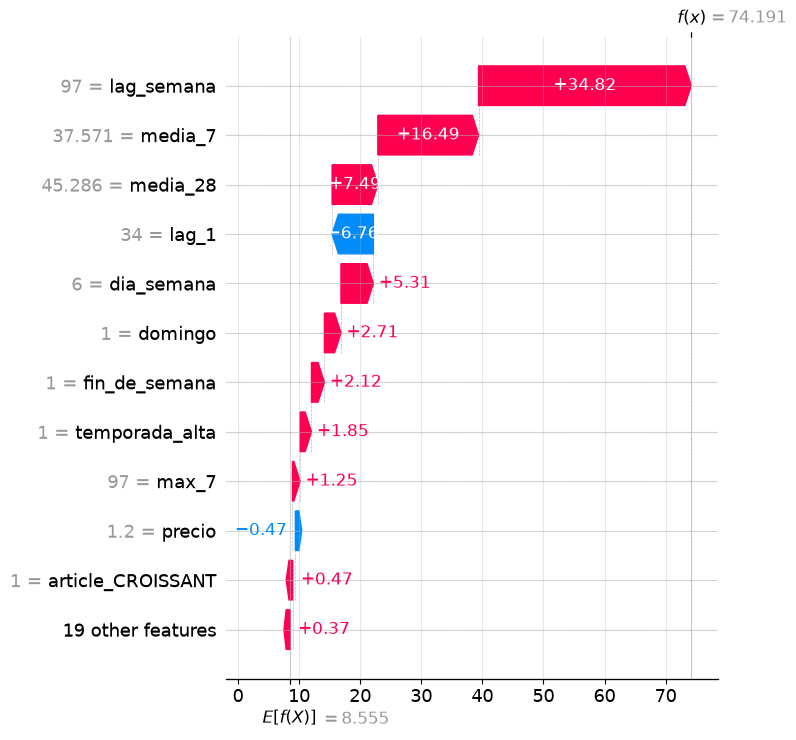

In [29]:
fila = test.reset_index(drop=True)
idx = fila[(fila["article"] == "CROISSANT") & (fila["dia_semana"] == 6)].index[0]
caso = fila.loc[idx]
print(f"{caso['article']} | {caso['date'].date()} (domingo) | real: {caso['unidades']:.0f} | predicho: {pred[idx]:.1f}")
shap.plots.waterfall(shap_values[idx], max_display=12, show=False)
plt.tight_layout(); plt.show()

**Cómo se lee.** La predicción arranca en el valor promedio del modelo, `E[f(X)]`. Cada barra muestra cuántas unidades suma (rojo) o resta (azul) cada variable para este croissant de domingo en temporada alta. Así el modelo deja de ser una caja negra: el panadero puede ver *por qué* se recomienda hornear esa cantidad.

## 9. Conclusiones

1. **Problema:** se planteó como una **regresión** que predice las unidades diarias de 16 productos de repostería, con **RMSE** como métrica principal, porque penaliza los errores grandes que generan merma o quiebre de stock.
2. **EDA:** la demanda depende sobre todo del **día de la semana** (el domingo vende más del doble que un día hábil) y de la **temporada turística** (julio y agosto). Se detectaron devoluciones (cantidades negativas), precios en texto y cierres semanales, y se trataron. Los outliers se mantuvieron porque son picos reales de demanda.
3. **Ingeniería de atributos:** se crearon variables de calendario, de categoría y de historia (lags y medias móviles) sin fuga de información, con One-Hot Encoding y escalado dentro de pipelines.
4. **Modelado y optimización:** se entrenaron Ridge, Árbol, Random Forest y XGBoost, y se optimizaron con GridSearchCV y RandomizedSearchCV sobre validación cruzada temporal. El árbol sin restricciones mostró overfitting (RMSE de train igual a 0), que se corrigió limitando la profundidad. En los ensambles, la optimización redujo la brecha entre train y test.
5. **Resultado:** el **Random Forest optimizado** logra un RMSE de 9,2 unidades frente a 13,0 de la regla actual (−30 %), con un R² de 0,885, y reduce alrededor de un 25 % el error de producción valorizado en euros.
6. **Explicabilidad:** SHAP muestra que el modelo aprende patrones con sentido de negocio (la venta de la semana anterior, el nivel reciente, los fines de semana y la temporada), lo que da confianza para usarlo en la planificación diaria del horneado.
7. **Limitaciones:** el período de test es solo de temporada alta, y en los productos de muy baja venta el modelo no mejora mucho a la regla simple.

**Próximos pasos:** incorporar el pronóstico del clima y el calendario de vacaciones escolares, y usar el modelo para generar cada noche una "orden de horneado" sugerida por producto.